# Prix des voitures d'occasion en Tunisie : régression + calibration

Ce notebook reproduit le modèle du dashboard **Valuer** :

1. **Modèle de valeur** entraîné sur 8 510 annonces CarDekho (Inde) : régression linéaire et Lasso sur `log(prix)`, avec la **marque et le modèle** de la voiture.
2. **Calibration tunisienne** sur 221 annonces réelles (autoprix.tn, automobile.tn, novembre 2026). Convertir les prix indiens au taux de change donne des prix 2 à 6 fois trop bas : la calibration corrige ce biais.

**Fichiers à charger dans Colab** (icône dossier à gauche, ou la cellule suivante) :
- `cars_merged_extended.csv`
- `tunisia_reference_listings.csv`

In [1]:
import os

FILES = ["cars_merged_extended.csv", "tunisia_reference_listings.csv"]
missing = [f for f in FILES if not os.path.exists(f)]
if missing:
    try:
        from google.colab import files  # dans Colab : fenêtre de chargement
        print("Chargez :", missing)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Placez {missing} à côté du notebook.")
print("Fichiers présents :", [f for f in FILES if os.path.exists(f)])

Fichiers présents : ['cars_merged_extended.csv', 'tunisia_reference_listings.csv']


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.linear_model import HuberRegressor, LassoCV, LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)

DATA_YEAR = 2022    # année de collecte des annonces CarDekho : âge = 2022 - année
MARKET_YEAR = 2026  # année des annonces tunisiennes (et des estimations)
MIN_MODEL_LISTINGS = 5

## 1. Les données

Le dataset contient maintenant une colonne **`model`**, extraite du nom de l'annonce (« Toyota Corolla Altis 1.8 VL CVT » → `Corolla`), avec des écritures unifiées (`KWID`/`Kwid`, `3 Series`/`3-Series`, « Maruti Suzuki Swift »/« Maruti Swift »). Les constructeurs cachés sous la marque `Other` (Kia, MG, Volvo…) ont leur propre marque. Le prix `selling_price` est en **lakh** (1 lakh = 100 000 roupies).

In [3]:
df = pd.read_csv("cars_merged_extended.csv").rename(columns={"model": "car_model"})
print(df.shape)
df.head()

(8510, 14)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,source,engine_cc,max_power_bhp,seats,brand,car_model
0,Mercedes-Benz E-Class E200,2011,9.50,65000,Petrol,Individual,Automatic,1,v4,1991.0,184.0,5.0,Mercedes-Benz,E-Class
1,Maruti Suzuki Swift DZire VDI,2011,2.75,65000,Diesel,Individual,Manual,0,v4,1248.0,74.0,5.0,Maruti,Swift Dzire
2,Maruti Suzuki Wagon R LXi,2011,2.65,41000,Petrol,Individual,Manual,1,v4,998.0,68.0,5.0,Maruti,Wagon R
3,Toyota Fortuner 3.0 MT,2010,10.00,127000,Diesel,Individual,Manual,2,v4,2982.0,171.0,7.0,Toyota,Fortuner
4,Honda City V,2016,7.30,51834,Petrol,Individual,Manual,1,v4,1497.0,117.0,5.0,Honda,City


In [4]:
print(df["brand"].nunique(), "marques,", df.groupby(["brand", "car_model"]).ngroups, "modèles")
df.groupby("brand")["car_model"].agg(annonces="size", modeles="nunique").sort_values("annonces", ascending=False).head(12)

27 marques, 229 modèles


,annonces,modeles
brand,,
Maruti,2480,24
Hyundai,1548,17
Mahindra,824,17
Tata,682,21
Honda,503,10
Toyota,445,11
Ford,399,9
Renault,245,10
Chevrolet,223,10


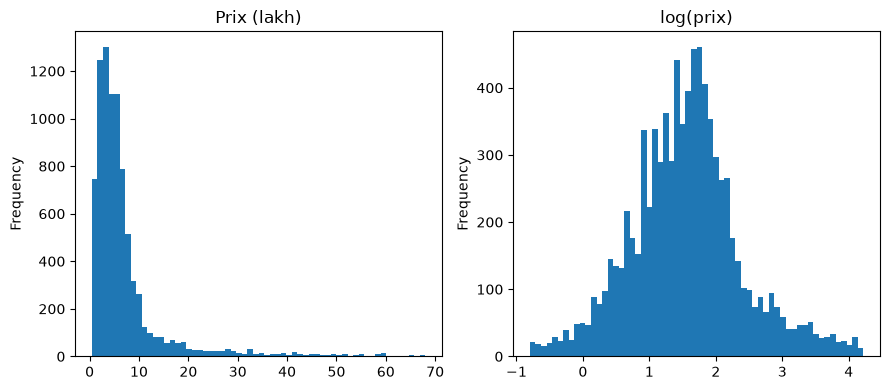

In [5]:
fig, ax = plt.subplots(1, 2)
df["selling_price"].plot.hist(bins=60, ax=ax[0], title="Prix (lakh)")
np.log(df["selling_price"]).plot.hist(bins=60, ax=ax[1], title="log(prix)")
plt.tight_layout(); plt.show()

Le prix est très asymétrique : on modélise donc **log(prix)**. Un coefficient se lit alors comme un pourcentage : +0,1 sur log(prix) ≈ +10,5 % sur le prix.

## 2. Variables

- `age` remplace `year`.
- `fuel` est encodé en **one-hot** (Essence = référence). Le notebook d'origine le codait 0 à 3, ce qui imposait un ordre sans sens.
- La **cylindrée** (`engine_cc`) est retirée : elle double la puissance (corrélation 0,74) et recevait un coefficient négatif, donc un moteur plus gros baissait le prix.
- `car` = marque + modèle en one-hot. Les modèles avec moins de 5 annonces sont regroupés dans « `<marque>|Other` ».

In [6]:
print("Corrélation cylindrée / puissance :", round(df["engine_cc"].corr(df["max_power_bhp"]), 2))

FUELS = ["Petrol", "Diesel", "CNG", "LPG"]
counts = df.groupby(["brand", "car_model"]).size()
known_cars = {f"{b}|{m}" for (b, m), n in counts.items() if n >= MIN_MODEL_LISTINGS}

def car_key(brand, car_model):
    key = f"{brand}|{car_model}"
    return key if key in known_cars else f"{brand}|Other"

def encode(d, ref_year, columns=None):
    """Matrice de variables. ref_year = année à laquelle s'applique le prix."""
    X = pd.DataFrame(index=d.index)
    X["age"] = (ref_year - d["year"]).clip(lower=0)
    X["km_driven"] = d["km_driven"]
    X["owner"] = d["owner"]
    X["seller_type"] = (d["seller_type"] == "Individual").astype(int)
    X["transmission"] = (d["transmission"] == "Automatic").astype(int)
    X["max_power_bhp"] = d["max_power_bhp"]
    X["seats"] = d["seats"]
    for f in FUELS[1:]:
        X[f"fuel_{f}"] = (d["fuel"] == f).astype(int)
    cars = pd.Series([car_key(b, m) for b, m in zip(d["brand"], d["car_model"])], index=d.index)
    dummies = pd.get_dummies(cars, prefix="car", dtype=int)
    X = pd.concat([X, dummies], axis=1)
    if columns is None:
        return X.drop(columns=sorted(dummies.columns)[0])  # drop_first
    return X.reindex(columns=columns, fill_value=0)

X = encode(df, DATA_YEAR)
y = np.log(df["selling_price"])
columns = list(X.columns)
print(X.shape[1], "variables dont", sum(c.startswith("car_") for c in columns), "pour la marque + modèle")

Corrélation cylindrée / puissance : 0.74
188 variables dont 178 pour la marque + modèle


## 3. Entraînement : régression linéaire et Lasso

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

models = {
    "linear": LinearRegression().fit(X_train_s, y_train),
    "lasso": LassoCV(cv=5, random_state=0).fit(X_train_s, y_train),
}

def evaluate(model, Xs, y_log):
    p = model.predict(Xs)
    return {"R2 log": metrics.r2_score(y_log, p),
            "R2 prix": metrics.r2_score(np.exp(y_log), np.exp(p)),
            "MAE (lakh)": metrics.mean_absolute_error(np.exp(y_log), np.exp(p))}

pd.DataFrame({f"{n} ({s})": evaluate(m, Xs, ys)
              for n, m in models.items()
              for s, Xs, ys in [("train", X_train_s, y_train), ("test", X_test_s, y_test)]}).round(3)

,linear (train),linear (test),lasso (train),lasso (test)
R2 log,0.943,0.936,0.942,0.933
R2 prix,0.933,0.927,0.922,0.909
MAE (lakh),0.977,1.029,1.020,1.094


### Ce qu'apporte le modèle de voiture
Même pipeline, avec la marque seule (comme le notebook d'origine) :

In [8]:
def brand_only(d):
    Xb = encode(d.assign(car_model="Other"), DATA_YEAR)
    return Xb

Xb = brand_only(df)
Xb_tr, Xb_te = Xb.loc[X_train.index], Xb.loc[X_test.index]
sb = StandardScaler().fit(Xb_tr)
mb = LinearRegression().fit(sb.transform(Xb_tr), y_train)
pd.DataFrame({"marque seule": evaluate(mb, sb.transform(Xb_te), y_test),
              "marque + modèle": evaluate(models["linear"], X_test_s, y_test)}).round(3)

,marque seule,marque + modèle
R2 log,0.906,0.936
R2 prix,0.870,0.927
MAE (lakh),1.367,1.029


In [9]:
lin = models["linear"]
coefs = pd.Series(lin.coef_, index=columns)
print("Coefficients (variables standardisées, effet sur log(prix)) :")
coefs[[c for c in columns if not c.startswith("car_")]].sort_values().round(3)

Coefficients (variables standardisées, effet sur log(prix)) :


age             -0.403
km_driven       -0.039
owner           -0.036
seats           -0.019
seller_type     -0.008
fuel_CNG         0.005
fuel_LPG         0.010
transmission     0.039
fuel_Diesel      0.073
max_power_bhp    0.203
dtype: float64

Tous les effets vont dans le bon sens : l'âge, les kilomètres et le nombre de propriétaires baissent le prix ; la puissance et la boîte automatique l'augmentent.

## 4. Calibration sur le marché tunisien

Le modèle a appris des **prix indiens**. Comparons ses prédictions, converties au taux de change (1 lakh ≈ 3 150 DT), à de vraies annonces tunisiennes.

In [10]:
tn = pd.read_csv("tunisia_reference_listings.csv").rename(columns={"model": "car_model"})
print(len(tn), "annonces tunisiennes")
tn.groupby(["brand", "car_model"]).size().rename("annonces").to_frame()

221 annonces tunisiennes


annonces
brand         car_model          
Ford          Fiesta           36
Hyundai       Creta             1
              Tucson           20
              i10              31
              i20              11
Maruti        Swift            39
Mercedes-Benz C-Class          26
Nissan        Micra            17
Toyota        Corolla          11
Volkswagen    Polo             29

In [11]:
# Caractéristiques typiques de chaque modèle (les annonces tunisiennes ne donnent ni la puissance ni les places)
cars_all = pd.Series([car_key(b, m) for b, m in zip(df["brand"], df["car_model"])], index=df.index)
typical = {car: {"transmission": g["transmission"].mode()[0],
                 "max_power_bhp": g["max_power_bhp"].median(),
                 "seats": int(g["seats"].mode()[0])}
           for car, g in df.groupby(cars_all)}

def prepare_tn(t):
    t = t.copy()
    spec = pd.DataFrame([typical[car_key(b, m)] for b, m in zip(t["brand"], t["car_model"])], index=t.index)
    stated = t["transmission"].fillna("").astype(str)
    t["transmission"] = stated.where(stated != "", spec["transmission"])
    t["max_power_bhp"], t["seats"] = spec["max_power_bhp"], spec["seats"]
    t["owner"], t["seller_type"] = 0, "Individual"
    return t

tn = prepare_tn(tn)
tn["age"] = (MARKET_YEAR - tn["year"]).clip(lower=0)
tn["log_pred_lakh"] = models["linear"].predict(scaler.transform(encode(tn, MARKET_YEAR, columns)))
tn["prix_converti"] = np.exp(tn["log_pred_lakh"]) * 3150
tn["ratio"] = tn["price_tnd"] / tn["prix_converti"]
tn.groupby(pd.cut(tn["age"], [-1, 3, 6, 10, 15, 40]), observed=True)["ratio"].median().round(2).rename("prix tunisien / prix converti")

age
(-1, 3]     2.15
(3, 6]      2.46
(6, 10]     3.61
(10, 15]    4.79
(15, 40]    6.08
Name: prix tunisien / prix converti, dtype: float64

Les voitures coûtent environ **2 fois plus cher** en Tunisie quand elles sont récentes, et jusqu'à **6 fois** quand elles sont anciennes : les droits d'importation rendent le neuf cher, et les voitures perdent moins de valeur. Un simple taux de change ne peut donc pas marcher.

On ajuste :

$$\log(\text{prix}_{TND}) = a + b\cdot\text{âge} + c\cdot\log(\text{prix prédit en lakh})$$

avec une **régression de Huber** (robuste aux annonces aberrantes). Pour une erreur honnête, chaque modèle de voiture est prédit par une calibration ajustée **sans lui** (leave-one-model-out).

In [12]:
def design(t):
    return np.c_[np.ones(len(t)), t["age"], t["log_pred_lakh"]]

def fit_calibration(t):
    return HuberRegressor(fit_intercept=False, alpha=0.0, max_iter=1000).fit(design(t), np.log(t["price_tnd"])).coef_

lomo = pd.Series(index=tn.index, dtype=float)
for g in tn["car_model"].unique():
    test = tn["car_model"] == g
    coef = fit_calibration(tn[~test])
    lomo[test] = np.exp(design(tn[test]) @ coef)

ape_cal = (lomo - tn["price_tnd"]).abs() / tn["price_tnd"]
ape_fx = (tn["prix_converti"] - tn["price_tnd"]).abs() / tn["price_tnd"]
print(f"Erreur médiane, taux de change seul : {ape_fx.median():.1%}")
print(f"Erreur médiane, calibration (modèle non vu) : {ape_cal.median():.1%}")

a, b, c = fit_calibration(tn)
print(f"\nCalibration finale : a = {a:.3f}, b = {b:.4f}, c = {c:.3f}")

Erreur médiane, taux de change seul : 62.6%
Erreur médiane, calibration (modèle non vu) : 14.7%

Calibration finale : a = 9.677, b = 0.0131, c = 0.565


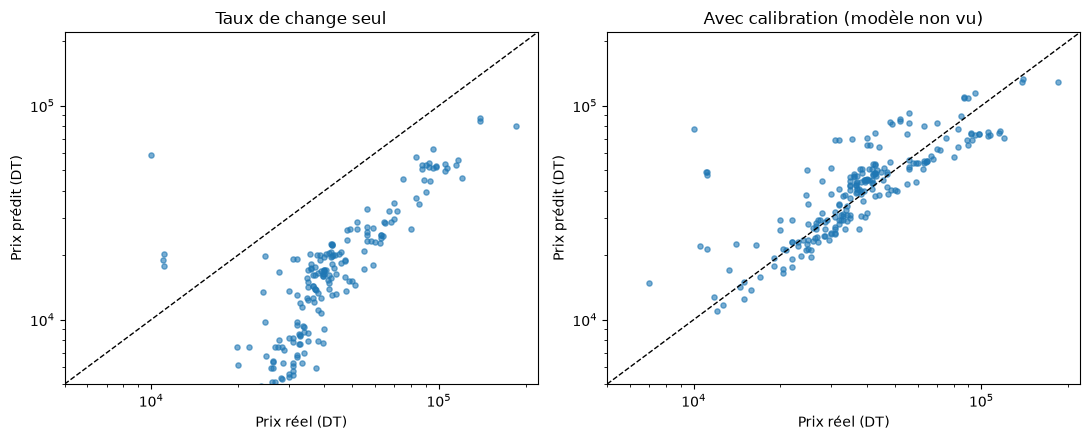

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for axis, pred, title in [(ax[0], tn["prix_converti"], "Taux de change seul"), (ax[1], lomo, "Avec calibration (modèle non vu)")]:
    axis.scatter(tn["price_tnd"], pred, s=14, alpha=0.6)
    lim = [5000, 220000]
    axis.plot(lim, lim, "k--", lw=1)
    axis.set(xscale="log", yscale="log", xlim=lim, ylim=lim, title=title, xlabel="Prix réel (DT)", ylabel="Prix prédit (DT)")
plt.tight_layout(); plt.show()

## 5. Estimer le prix d'une voiture

In [14]:
log_err = np.log(tn["price_tnd"] / lomo)
q10, q90 = np.quantile(log_err, [0.10, 0.90])

def estimer_prix(brand, car_model, year, km_driven=None, fuel=None, transmission=None,
                 owner=0, seller_type="Individual", max_power_bhp=None, seats=None, model="linear"):
    """Prix estimé en DT et fourchette à 80 %. Les caractéristiques absentes prennent la valeur typique du modèle."""
    spec = typical[car_key(brand, car_model)]
    age = max(0, MARKET_YEAR - year)
    row = pd.DataFrame([{
        "brand": brand, "car_model": car_model, "year": year,
        "km_driven": km_driven if km_driven is not None else 18000 * max(age, 0.5),
        "fuel": fuel or df.loc[cars_all == car_key(brand, car_model), "fuel"].mode()[0],
        "transmission": transmission or spec["transmission"],
        "owner": owner, "seller_type": seller_type,
        "max_power_bhp": max_power_bhp or spec["max_power_bhp"], "seats": seats or spec["seats"],
    }])
    log_pred = models[model].predict(scaler.transform(encode(row, MARKET_YEAR, columns)))[0]
    prix = float(np.exp(a + b * age + c * log_pred))
    return round(prix, -2), round(prix * np.exp(q10), -2), round(prix * np.exp(q90), -2)

exemples = [("Hyundai", "i10", 2018, 140000), ("Volkswagen", "Polo", 2015, 170000),
            ("Toyota", "Corolla", 2020, 110000), ("Kia", "Seltos", 2022, 60000),
            ("Mercedes-Benz", "C-Class", 2012, 220000)]
pd.DataFrame([(f"{b} {m}", y, km, *estimer_prix(b, m, y, km)) for b, m, y, km in exemples],
             columns=["voiture", "année", "km", "prix (DT)", "bas 80 %", "haut 80 %"])

,voiture,année,km,prix (DT),bas 80 %,haut 80 %
0,Hyundai i10,2018,140000,33600.0,21100.0,42400.0
1,Volkswagen Polo,2015,170000,33300.0,21000.0,42100.0
2,Toyota Corolla,2020,110000,55400.0,34800.0,69900.0
3,Kia Seltos,2022,60000,70800.0,44600.0,89300.0
4,Mercedes-Benz C-Class,2012,220000,66500.0,41800.0,83900.0


## 6. Sauvegarder le modèle

Le fichier `model_tunisie.joblib` contient tout ce qu'il faut pour prédire : modèles, scaler, colonnes et calibration.

In [15]:
import joblib
joblib.dump({"models": models, "scaler": scaler, "columns": columns, "known_cars": sorted(known_cars),
             "calibration": {"a": a, "b_age": b, "c_log_pred": c, "q10": q10, "q90": q90},
             "typical": typical, "data_year": DATA_YEAR, "market_year": MARKET_YEAR}, "model_tunisie.joblib")
try:
    from google.colab import files
    files.download("model_tunisie.joblib")
except ImportError:
    print("Enregistré : model_tunisie.joblib")

Enregistré : model_tunisie.joblib


## Limites

- La calibration repose sur **221 annonces et 10 modèles**. L'erreur médiane est d'environ 15 % sur un modèle jamais vu, mais les modèles rares en Tunisie (Mahindra, Tata…) restent extrapolés.
- Ce sont des **prix demandés** dans des annonces, pas des prix de vente conclus.
- Pour aller plus loin : collecter davantage d'annonces tunisiennes (marques françaises comme Peugeot et Renault, absentes ou rares dans CarDekho) et entraîner directement sur ces données.